# W05 — Analitik Konvolüsyon (Elle Çözüm Odaklı)

**Amaçlar**
- Ayrık zamanda konvolüsyonun **toplam tanımıyla** hesaplanması:  
  $\displaystyle (x*h)[n]=\sum_{k=-\infty}^{\infty} x[k]\,h[n-k]$
- **Destek (support)** ve **örtüşen k aralığının** sistematik olarak bulunması.
- Sınırlar kurulduktan sonra **toplamın yazılması**, ardından **tek tek terimlerine (her k için)** ayrıştırılarak gösterilmesi.
- **Geometrik seri** kimlikleriyle **kapalı biçim**; gerekli yerlerde **sonsuz toplam** formülleri.
- Kısa Python kontrolleriyle doğrulama.

> Not: Bu defter, önce **elle çözüm** (adım adım), ardından **sayısal doğrulama** yapacak biçimde hazırlanmıştır.


# 0) Özellikler

**Tanım (DT):**

$\displaystyle (x*h)[n]=\sum_{k=-\infty}^{\infty} x[k]\,h[n-k]$

**1) Sifting & Kimlik**

$\displaystyle x[n]*\delta[n]=x[n],\qquad x[n]*\delta[n-n_0]=x[n-n_0]$

$\displaystyle x[n]=\sum_{m}x[m]\delta[n-m]\ \Rightarrow\ (x*h)[n]=\sum_m x[m]\,h[n-m]$

**2) Lineerlik (Dağılma)**

$\displaystyle x*(a\,h_1+b\,h_2)=a(x*h_1)+b(x*h_2),\qquad (a\,x_1+b\,x_2)*h=a(x_1*h)+b(x_2*h)$

**3) Değişme (Komütatif)**

$\displaystyle (x*h)[n]=(h*x)[n]$

**4) Birleşme (Assosiyatif)**

$\displaystyle x*(h*g)=(x*h)*g$
*(Ardışık iki LTI blok tek eşdeğer LTI bloktur.)*

**5) Zamanda Kaydırma**

$\displaystyle x[n-n_0]*h[n]=(x*h)[n-n_0],\qquad x[n]*h[n-n_0]=(x*h)[n-n_0]$

**6) Ölçekleme**

$\displaystyle (a\,x)*h=a\,(x*h)$

**7) Destek & Uzunluk (Sonlu diziler)**

$\displaystyle x$ uzunluğu $\displaystyle L_x$, $\displaystyle h$ uzunluğu $\displaystyle L_h$ ise:

$\displaystyle \operatorname{len}(x*h)=L_x+L_h-1$

Toplam yalnız **örtüşen $\displaystyle k$** değerlerinde çalışır.

**8) Nedensellik Koruma**

$\displaystyle x,h$ kausal ise $\displaystyle y=x*h$ de kausaldır.

**9) Üstel Girişler (Kausal) — Kapalı Biçim**

$\displaystyle x[n]=a^n u[n],\quad h[n]=b^n u[n]\ \Rightarrow\ (x*h)[n]=\sum_{k=0}^{n} a^k b^{\,n-k}$

$\displaystyle a\neq b:\ (x*h)[n]=\frac{b^{\,n+1}-a^{\,n+1}}{b-a}\,u[n],\qquad a=b:\ (x*h)[n]=(n+1)a^{\,n}u[n]$

**10) Sonsuz Toplam (Geometrik Seri) Kısayolları**

$\displaystyle \sum_{n=0}^{\infty} r^{n}=\frac{1}{1-r},\quad \sum_{n=0}^{\infty} n\,r^{n}=\frac{r}{(1-r)^2},\quad |r|<1$


**Tipik Hatalar**
- Örtüşmeyen $\displaystyle k$ değerlerini toplama dahil etmek,
- Parçalı sonucu $\displaystyle u[\cdot]$ ile **kapamamak**,
- $\displaystyle h[n-k]$ içindeki **kaymayı** yanlış yönetmek,
- Aritmetik vs. geometrik seri **kimliklerini karıştırmak**.

## 1) Örnek A — Kutu Sinyaller ve Ortalama FIR
**Verilenler**
- $\displaystyle x[n]=u[n]-u[n-3]$  (uzunluk 3: $\displaystyle n=0,1,2$)
- $\displaystyle h[n]=\tfrac{1}{3}\big(u[n]-u[n-3]\big)$  (uzunluk 3: $\displaystyle n=0,1,2$)

**Adım 1 — Destekler**
- $\displaystyle x[k]\neq 0$ için $\displaystyle k\in\{0,1,2\}$
- $\displaystyle h[n-k]\neq 0$ için $\displaystyle n-k\in\{0,1,2\}\Rightarrow k\in\{n-2,n-1,n\}$

**Adım 2 — Örtüşen k Aralığı**
$\displaystyle \max(0,\,n-2)\ \le k \le\ \min(2,\,n)$

**Adım 3 — Toplamın Yazılması**
$\displaystyle (x*h)[n]=\sum_{k=\max(0,n-2)}^{\min(2,n)} x[k]\cdot \tfrac{1}{3}$

**Adım 4 — Terimlere Ayırma (her k)**
- Her geçerli $\displaystyle k$ için katkı $\displaystyle \tfrac{1}{3}$ (çünkü $\displaystyle x[k]=1$, $\displaystyle h[\cdot]=\tfrac{1}{3}$)
- Geçerli $\displaystyle k$ sayısı kadar $\displaystyle \tfrac{1}{3}$ toplanır

**Adım 5 — Parçalı Sonuç**
$\displaystyle y[n]=\begin{cases}
0,& n<0\\
\frac{1}{3},& n=0\\
\frac{2}{3},& n=1\\
1,& n=2\\
\frac{2}{3},& n=3\\
\frac{1}{3},& n=4\\
0,& n\ge 5
\end{cases}$

**Fiziksel Benzetme:** Bu, 3 günlük hareketli ortalama filtresine karşılık gelir. $\displaystyle x[n]$ günlük veriler, $\displaystyle h[n]$ ise ortalamalı filtredir.

Aşağıda, **n=0..4** için toplamı **tek tek k terimlerine ayırarak** gösteriyoruz.

In [1]:
# Örnek A: per-k genişletme (elle yaptığımızı sayısal olarak da gösterelim)
def box_signal(length, scale=1.0):
    # returns [1,1,...,1] of given length, scaled
    return [scale]*length

# BURAYI DEĞİŞTİREREK GÖZLEM YAPABİLİRSİNİZ
k1 = 3  # x sinyalinin uzunluğu
k2 = 3  # h sinyalinin uzunluğu
x_value = 1.0    # x sinyalinin değeri
h_value = 1/3    # h sinyalinin değeri

x = box_signal(k1, x_value)
h = box_signal(k2, h_value)

print(f"x = {x}")  # x sinyalini göster
print(f"h = {h}")  # h sinyalini göster

import numpy as np

def conv_disc(x, h):
    y = np.convolve(x, h)  # purely numeric convolution for check
    return y

y = conv_disc(x, h)  

# Per-k expansion for all n
from pprint import pprint
expansions = {}
for n in range(len(x) + len(h) - 1):
    terms = []
    # Genel formül: k_min = max(0, n - (len(h)-1)), k_max = min(len(x)-1, n)
    k_min = max(0, n - (len(h) - 1))
    k_max = min(len(x) - 1, n)
    
    for k in range(k_min, k_max + 1):
        # h[n-k] değeri: eğer (n-k) h'nin destek aralığındaysa h_value, değilse 0
        if 0 <= (n - k) < len(h):
            h_val = h_value
        else:
            h_val = 0
        term_value = x[k] * h_val
        terms.append((k, term_value))
    expansions[n] = terms

print(f"\nPer-k terimleri (n=0..{len(x)+len(h)-2}):")
for n in range(len(x) + len(h) - 1):
    total = sum(t for k, t in expansions[n])
    print(f"n={n}: k={expansions[n][0][0]}..{expansions[n][-1][0] if expansions[n] else 'none'} -> {expansions[n]}  -> sum={total:.6f}")

print(f"\nSayısal konvolüsyon sonucu: {y.tolist()}")

# Doğrulama
print(f"\nDoğrulama:")
print(f"x uzunluğu: {len(x)}, h uzunluğu: {len(h)}")
print(f"Sonuç uzunluğu: {len(y)} (beklenen: {len(x) + len(h) - 1})")

x = [1.0, 1.0, 1.0]
h = [0.3333333333333333, 0.3333333333333333, 0.3333333333333333]

Per-k terimleri (n=0..4):
n=0: k=0..0 -> [(0, 0.3333333333333333)]  -> sum=0.333333
n=1: k=0..1 -> [(0, 0.3333333333333333), (1, 0.3333333333333333)]  -> sum=0.666667
n=2: k=0..2 -> [(0, 0.3333333333333333), (1, 0.3333333333333333), (2, 0.3333333333333333)]  -> sum=1.000000
n=3: k=1..2 -> [(1, 0.3333333333333333), (2, 0.3333333333333333)]  -> sum=0.666667
n=4: k=2..2 -> [(2, 0.3333333333333333)]  -> sum=0.333333

Sayısal konvolüsyon sonucu: [0.3333333333333333, 0.6666666666666666, 1.0, 0.6666666666666666, 0.3333333333333333]

Doğrulama:
x uzunluğu: 3, h uzunluğu: 3
Sonuç uzunluğu: 5 (beklenen: 5)


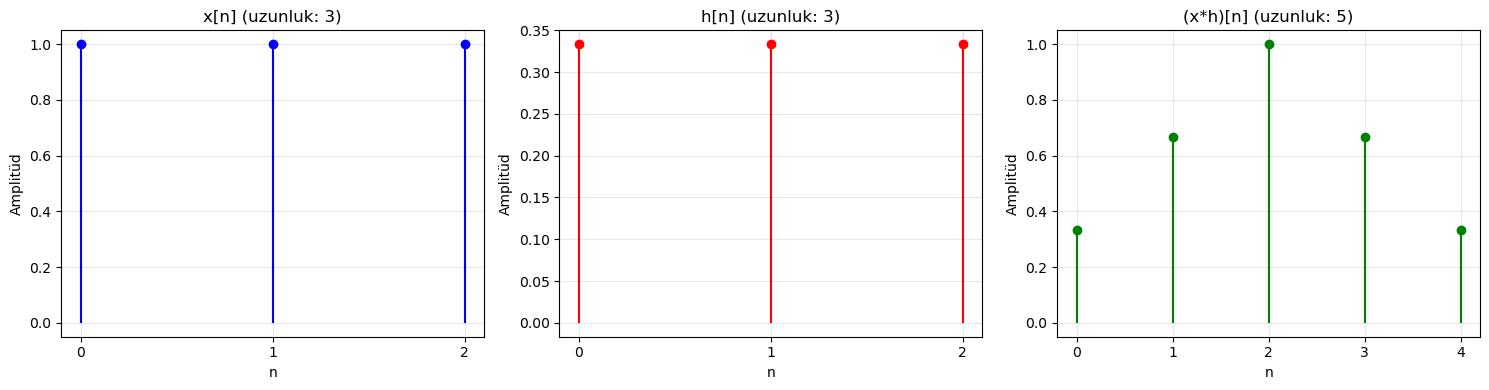


Grafik Bilgisi:
x[n] destek: n = 0..2
h[n] destek: n = 0..2
(x*h)[n] destek: n = 0..4
Toplam destek uzunluğu: 3 + 3 - 1 = 5 (doğrulandı)


In [2]:
# Grafikleri çizdirme
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# x sinyali grafiği
n_x = range(len(x))
ax1.stem(n_x, x, linefmt='b-', markerfmt='bo', basefmt=' ')
ax1.set_title(f'x[n] (uzunluk: {len(x)})')
ax1.set_xlabel('n')
ax1.set_ylabel('Amplitüd')
ax1.grid(True, alpha=0.3)
ax1.set_xticks(n_x)

# h sinyali grafiği
n_h = range(len(h))
ax2.stem(n_h, h, linefmt='r-', markerfmt='ro', basefmt=' ')
ax2.set_title(f'h[n] (uzunluk: {len(h)})')
ax2.set_xlabel('n')
ax2.set_ylabel('Amplitüd')
ax2.grid(True, alpha=0.3)
ax2.set_xticks(n_h)

# Konvolüsyon sonucu grafiği
n_y = range(len(y))
ax3.stem(n_y, y, linefmt='g-', markerfmt='go', basefmt=' ')
ax3.set_title(f'(x*h)[n] (uzunluk: {len(y)})')
ax3.set_xlabel('n')
ax3.set_ylabel('Amplitüd')
ax3.grid(True, alpha=0.3)
ax3.set_xticks(n_y)

plt.tight_layout()
plt.show()

# Grafik bilgileri
print(f"\nGrafik Bilgisi:")
print(f"x[n] destek: n = 0..{len(x)-1}")
print(f"h[n] destek: n = 0..{len(h)-1}")
print(f"(x*h)[n] destek: n = 0..{len(y)-1}")
print(f"Toplam destek uzunluğu: {len(x)} + {len(h)} - 1 = {len(y)} (doğrulandı)")

## 2) Örnek B — Üstel Kausal Diziler (Kapalı Biçim ve Sonsuz Toplam Kimlikleri)
**Verilenler**
- $\displaystyle x[n]=a^{n}u[n]$, $\displaystyle |a|<1$
- $\displaystyle h[n]=b^{n}u[n]$, $\displaystyle |b|<1$

**Fiziksel Benzetme:** Bu, iki üstel bozunan sistemin seri bağlanmasına karşılık gelir (örneğin, radyoaktif bozunma zinciri).

**Adım 1 — Destekler ve Örtüşen k Aralığı**
- $\displaystyle x[k]\neq 0$ için $\displaystyle k\ge 0$
- $\displaystyle h[n-k]\neq 0$ için $\displaystyle n-k\ge 0\Rightarrow k\le n$
- Dolayısıyla $\displaystyle k=0,1,\dots,n$

**Adım 2 — Toplamın Yazılması**
$\displaystyle y[n]=\sum_{k=0}^{n} a^k\,b^{\,n-k}$

**Adım 3 — Terimlere Ayırma (her k)**
$\displaystyle y[n]=b^{n}\sum_{k=0}^{n}\Big(\frac{a}{b}\Big)^{k}$

**Kapalı Biçim (Geometrik Seri)**
- $\displaystyle a\neq b$ için:
$\displaystyle y[n]=\frac{b^{\,n+1}-a^{\,n+1}}{\,b-a\,}\,u[n]$
- $\displaystyle a=b$ için:
$\displaystyle y[n]=(n+1)\,a^{\,n}\,u[n]$

Aşağıda hem **per-k genişletmesini** hem de **sayısal doğrulamayı** gösteriyoruz.

In [3]:
import numpy as np

def y_closed_form(n, a, b):
    if abs(a-b) > 1e-12:
        return (b**(n+1) - a**(n+1)) / (b - a)
    else:
        return (n+1)*(a**n)

def y_sum(n, a, b):
    # explicit sum with per-k terms
    s = 0.0
    terms = []
    for k in range(0, n+1):
        term = (a**k)*(b**(n-k))
        terms.append((k, term))
        s += term
    return s, terms

a, b = 0.7, 0.5
N = 8
print(f"a={a}, b={b}")
for n in range(N+1):
    s, terms = y_sum(n, a, b)
    cf = y_closed_form(n, a, b)
    print(f"n={n}: sum={s:.8f}  closed_form={cf:.8f}  diff={abs(s-cf):.2e}")
    # Uncomment to see per-k terms:
    # print("  terms:", terms)

a=0.7, b=0.5
n=0: sum=1.00000000  closed_form=1.00000000  diff=0.00e+00
n=1: sum=1.20000000  closed_form=1.20000000  diff=0.00e+00
n=2: sum=1.09000000  closed_form=1.09000000  diff=0.00e+00
n=3: sum=0.88800000  closed_form=0.88800000  diff=1.11e-16
n=4: sum=0.68410000  closed_form=0.68410000  diff=1.11e-16
n=5: sum=0.51012000  closed_form=0.51012000  diff=0.00e+00
n=6: sum=0.37270900  closed_form=0.37270900  diff=0.00e+00
n=7: sum=0.26870880  closed_form=0.26870880  diff=0.00e+00
n=8: sum=0.19200241  closed_form=0.19200241  diff=0.00e+00


### Sonsuz Toplam Kimlikleri (Referans)
Kısaca ihtiyaç duyulabilecek geometrik seri kimlikleri:

- $\displaystyle \sum_{n=0}^{\infty} r^{n} = \frac{1}{1-r}$, $\displaystyle |r|<1$
- $\displaystyle \sum_{n=0}^{\infty} n\,r^{n} = \frac{r}{(1-r)^2}$, $\displaystyle |r|<1$
- $\displaystyle \sum_{n=0}^{\infty} r^{n+m} = \frac{r^m}{1-r}$, $\displaystyle |r|<1$
- $\displaystyle \sum_{n=0}^{N} r^{n} = \frac{1-r^{N+1}}{1-r}$, $\displaystyle r\neq 1$

**Not:** Bu kimlikler, belirli durumlarda konvolüsyon toplamını kapalı biçime indirgerken kullanışlıdır
(ör., $\displaystyle a=b$ özel durumu; ya da $\displaystyle \sum a^k$ biçimli parçaların doğrudan indirgenmesi).

## 3) Örnek C — Dirac Ayrışımı ile Hızlı Sonuç
**Verilen**
$\displaystyle x[n]=2\delta[n]+\delta[n-1], \quad h[n]\ \text{(genel)}$

**Doğrudan Sonuç (sifting):**
$\displaystyle y[n]=(x*h)[n]=2h[n]+h[n-1]$

**Fiziksel Benzetme:** Bu, bir sinyalin iki farklı anda örneklenmiş halinin bir sisteme uygulanmasıdır.

**Per-k Açılım Gösterimi**
$\displaystyle (x*h)[n]=\sum_{k=-\infty}^{\infty} x[k]\,h[n-k]=2\,h[n-0]+1\cdot h[n-1]+0\ (\text{diğer }k'ler)$

Aşağıda sembolik bir $\displaystyle h$ için bu eşitliği sayısal olarak da doğruluyoruz.

In [4]:
import numpy as np

# Dirac comb example with finite support h
h = np.array([0.0, 1.0, 0.5, 0.0])  # e.g., h[0]=0,h[1]=1,h[2]=0.5,h[3]=0
x = np.zeros(6); x[0] = 2.0; x[1] = 1.0  # 2δ[n] + δ[n-1]

y_numeric = np.convolve(x, h)
# Expected y[n] = 2h[n] + h[n-1] -> compute explicitly on same length
y_expected = np.zeros_like(y_numeric)
for n in range(len(y_numeric)):
    t = 0.0
    if 0 <= n < len(h): t += 2.0*h[n]
    if 0 <= n-1 < len(h): t += 1.0*h[n-1]
    y_expected[n] = t

print("Sayısal konvolüsyon:", y_numeric.tolist())
print("Beklenen (2h[n]+h[n-1]):", y_expected.tolist())
print("Fark (norm):", float(np.linalg.norm(y_numeric - y_expected)))

Sayısal konvolüsyon: [0.0, 2.0, 2.0, 0.5, 0.0, 0.0, 0.0, 0.0, 0.0]
Beklenen (2h[n]+h[n-1]): [0.0, 2.0, 2.0, 0.5, 0.0, 0.0, 0.0, 0.0, 0.0]
Fark (norm): 0.0


## 4) Mini Alıştırmalar (Ödev Olarak Çözünüz)
1. $\displaystyle x[n]=u[n]-u[n-4]$, $\displaystyle h[n]=u[n]-u[n-3]$. **Destekleri yaz**, **örtüşen k aralığını bul**, $\displaystyle (x*h)[n]$**'yi parçalı olarak** çıkar.
2. $\displaystyle x[n]=\delta[n]-\delta[n-2]$, $\displaystyle h[n]=\alpha^{n}u[n]$ ($\displaystyle |\alpha|<1$). $\displaystyle y[n]$**'yi** sifting ile yaz.
3. $\displaystyle x[n]=a^n u[n]$, $\displaystyle h[n]=u[n]-u[n-3]$. **Toplamı yaz**, **k sınırlarını kur**, **kapalı biçimi** elde et.  
   İpucu: $\displaystyle k\in[0,\min(n,2)]$.

> İsteğe bağlı: Sonuçları kısa Python kodu ile doğrulayın (grafik şart değil).

## 5) Kısa Doğrulama Yardımcıları
Aşağıdaki fonksiyonlar, elde ettiğiniz sonuçları hızla kontrol etmeniz için sağlanmıştır.

In [5]:
import numpy as np

def u(n):
    return 1.0 if n>=0 else 0.0

def seq_from_step(start, length, scale=1.0):
    # returns list representing scale*(u[n-start]-u[n-(start+length)]), aligned at n=0..(start+length+length-2)
    arr = [0.0]*(start+length)
    for i in range(start, start+length):
        arr[i] = scale
    return arr

def finite_conv(x, h):
    return np.convolve(np.array(x, dtype=float), np.array(h, dtype=float)).tolist()

# Örnek: x=[0,1,2,1,0], h=[1/3,1/3,1/3]
x = [0,1,2,1,0]
h = [1/3,1/3,1/3]
print("Doğrulama örneği:", finite_conv(x,h))

Doğrulama örneği: [0.0, 0.3333333333333333, 1.0, 1.3333333333333333, 1.0, 0.3333333333333333, 0.0]


## 6) Sık Yapılan Hatalar ve Çözümleri

### ⚠️ Yaygın Hatalar

1. **Sınır Hataları**: 
   - **Hata:** $\displaystyle k_{\text{min}} = n-2$, $\displaystyle k_{\text{max}} = n$ yazmak (destek kontrolü yapmadan)
   - **Doğrusu:** $\displaystyle k_{\text{min}} = \max(0, n-2)$, $\displaystyle k_{\text{max}} = \min(2, n)$

2. **İndis Kaymaları**:
   - **Hata:** $\displaystyle h[n-k]$ yerine $\displaystyle h[k-n]$ yazmak
   - **Doğrusu:** Konvolüsyon tanımında her zaman $\displaystyle h[n-k]$ kullanılır

3. **Birim Basamak Unutmak**:
   - **Hata:** $\displaystyle x[n]=a^n$ yazmak ($\displaystyle u[n]$'i unutmak)
   - **Doğrusu:** $\displaystyle x[n]=a^n u[n]$ şeklinde kausal olduğunu belirtmek

4. **Geometrik Seri Uygulama**:
   - **Hata:** $\displaystyle \sum_{k=0}^{n} r^k = \frac{1-r^{n+1}}{1-r}$ formülünü $\displaystyle r=1$ için kullanmak
   - **Doğrusu:** $\displaystyle r=1$ ise toplam $\displaystyle n+1$'e eşittir

### ✅ Doğrulama İpuçları

1. **Destek Kontrolü**: Sonucun destek uzunluğu = len(x) + len(h) - 1 olmalı
2. **Sınır Değerleri**: $\displaystyle n\rightarrow -\infty$ ve $\displaystyle n\rightarrow \infty$ için sonuç sıfıra gitmeli
3. **Enerji Korunumu**: Gerekirse enerji hesabı yaparak kontrol edin

## 7) Gerçek Hayat Uygulama Örnekleri

### 📊 Sinyal İşleme Uygulamaları

1. **Hareketli Ortalama Filtresi** (Örnek A)
   - **Uygulama:** Hisse senedi fiyatlarının düzleştirilmesi
   - **Açıklama:** Kısa vadeli dalgalanmaları azaltır, uzun vadeli trendi gösterir

2. **Üstel Ortalama Filtresi** (Örnek B)
   - **Uygulama:** Sensör verilerinin filtrelenmesi
   - **Açıklama:** Daha yeni ölçümleri daha fazla ağırlıklandırır

3. **Echo/Yankı Efekti** (Örnek C benzeri)
   - **Uygulama:** Ses işlemede yankı efekti
   - **Açıklama:** $\displaystyle h[n]=\delta[n]+\alpha\delta[n-D]$ şeklinde bir darbe tepkisi

### 🔬 Fiziksel Sistem Modellemeleri

1. **Radyoaktif Bozunma Zinciri**: 
   - Üstel konvolüsyon, ardışık bozunma süreçlerini modellemek için kullanılır

2. **Isı Transferi**: 
   - Bir çubuğun farklı noktalarındaki sıcaklık dağılımı konvolüsyonla modellenebilir

### 🎯 Öğrenme Çıktıları Kontrol Listesi

- [ ] Ayrık konvolüsyon tanımını anlayabiliyorum
- [ ] Destek aralığını doğru belirleyebiliyorum
- [ ] Örtüşen k aralığını bulabiliyorum
- [ ] Toplamı terim terim yazabiliyorum
- [ ] Geometrik seri kimliklerini uygulayabiliyorum
- [ ] Kapalı form çözümler türetebiliyorum
- [ ] Sayısal doğrulama yapabiliyorum
- [ ] Fiziksel sistemleri konvolüsyonla modelleyebiliyorum